# AutoExperiment - Advanced Usage

This notebook covers advanced features of AutoExperiment:
1. Custom transformations (lags, diffs, log, accumulations, growth, squares)
2. Sign constraints from economic theory
3. Adjusting ranking weights
4. Specifying required tests
5. Controlling search budget (`max_combinations`)
6. Parallelization (`n_jobs`)
7. Analyzing selected vs. rejected variables
8. BIC path analysis
9. Exporting results

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from panelbox import AutoExperiment, load_grunfeld
from panelbox.autoexperiment import VariableTransformer, ModelRanker

data = load_grunfeld()
print(f"Grunfeld: {data.shape[0]} obs, {data['firm'].nunique()} firms, {data['year'].nunique()} years")

Grunfeld: 200 obs, 10 firms, 20 years


---
## 1. Custom Transformations

AutoExperiment can automatically generate transformed variables from your candidates.

| Key | Description | Example |
|-----|-------------|---------|
| `lag` | Lagged values | `[1, 2]` -> `L1_x`, `L2_x` |
| `diff` | First difference | `True` -> `D_x` |
| `log` | Natural log (x > 0 only) | `True` -> `log_x` |
| `acum` | Rolling mean (accumulation) | `[3]` -> `acum3_x` |
| `growth` | Percentage change | `True` -> `growth_x` |
| `sq` | Squared | `True` -> `sq_x` |

In [2]:
# Preview transformations before running the full pipeline
transformer = VariableTransformer(
    data=data,
    entity_col="firm",
    time_col="year",
    transformations={
        "lag": [1, 2],
        "diff": True,
        "log": True,
        "growth": True,
    },
)

transformed = transformer.transform(["value", "capital"])
print(transformer.summary())
print(f"\nValid transformations: {transformer.get_valid_transformations()}")

=== VariableTransformer Summary ===
Transformacoes geradas:     10
Transformacoes validas:     8
Descartadas por NaN > 30%: 0
Descartadas por multicolinearidade: 2

Removidas (multicolinearidade > 0.95):
  L2_capital
  L2_value

Valid transformations: ['L1_value', 'D_value', 'log_value', 'growth_value', 'L1_capital', 'D_capital', 'log_capital', 'growth_capital']


In [3]:
# Run AutoExperiment with custom transformations
auto = AutoExperiment(
    data=data,
    depvar="invest",
    entity_col="firm",
    time_col="year",
    candidates=["value", "capital"],
    transformations={
        "lag": [1, 2],
        "diff": True,
        "log": True,
        "growth": True,
    },
    models=["pooled_ols", "fe", "re", "fd"],
    max_vars=5,
    verbose=1,
)

results = auto.run()
print("\n" + results.summary())

Phase 1: Variable transformations
  2 original + 8 transformed = 10 candidates
Phase 2: Forward stepwise selection
  Selecting for pooled_ols...
  [------------------------------] 0/4 Selection

  Selecting for fe...
  [#######-----------------------] 1/4 Selection

  Selecting for re...
  [###############---------------] 2/4 Selection

  Selecting for fd...
  [######################--------] 3/4 Selection

  [##############################] 4/4 Selection


...

    -> WARNING (BIC=1745.74, cov=robust)
  [#######-----------------------] 1/4 Estimation

    -> INVALID (BIC=1557.70, cov=robust)
  [###############---------------] 2/4 Estimation

    -> INVALID (BIC=1829.37, cov=robust)
  [######################--------] 3/4 Estimation

    -> VALID (BIC=nan, cov=nonrobust)
  [##############################] 4/4 Estimation


Phase 4: Hausman test (FE vs RE)
  Hausman: prefer RE (marked fe_capital_value_log_capital as WARNING)
Phase 5: Ranking
Done.

══════════════════════════════════════════════════
AutoExperiment Results
══════════════════════════════════════════════════
Best model: First Difference
Formula:    invest ~ capital + value + log_capital
BIC:        1745.7
R-squared:  0.823
Cov type:   nonrobust
Status:     VALID (all tests passed)
──────────────────────────────────────────────────
Models tested:     4
Combinations:      40
Variables tested:  9
Transformations:   4 types


---
## 2. Sign Constraints (Economic Theory as Filter)

Economic theory tells us that firm value and capital stock should have a **positive** effect on investment (Tobin's Q theory).

Sign constraints enforce this: models with wrong-signed coefficients are penalized in ranking.

In [4]:
auto_signs = AutoExperiment(
    data=data,
    depvar="invest",
    entity_col="firm",
    time_col="year",
    candidates=["value", "capital"],
    transformations={"lag": [1], "diff": True},
    sign_constraints={
        "value": "+",    # Theory: higher value -> more investment
        "capital": "+",  # Theory: more capital -> more investment
    },
    models=["fe", "re"],
    max_vars=4,
    verbose=0,
)

results_signs = auto_signs.run()
print(results_signs.summary())
print("\nTop models with sign constraints:")
results_signs.compare_top(n=3)

══════════════════════════════════════════════════
AutoExperiment Results
══════════════════════════════════════════════════
Best model: 
Formula:    
BIC:        
R-squared:  
Cov type:   
Status:     N/A
──────────────────────────────────────────────────
Models tested:     2
Combinations:      14
Variables tested:  6
Transformations:   2 types

Top models with sign constraints:


,model_type,formula,bic,aic,rsq,rsq_adj,classification,n_vars,cov_type,score
0,fe,invest ~ capital + value,1562.226253,1555.629618,0.789935,0.777644,INVALID,2,robust,1758.226253
1,re,invest ~ value + capital,1842.959525,1833.064573,0.800281,0.798254,INVALID,2,robust,2038.959525


---
## 3. Adjusting Ranking Weights

The `ModelRanker` uses a composite score with configurable weights:

| Component | Default | Description |
|-----------|---------|-------------|
| `criterion` | 0.50 | BIC/AIC (lower = better) |
| `tests` | 0.30 | Fraction of tests passed |
| `signs` | 0.15 | Sign constraint satisfaction |
| `parsimony` | 0.05 | Fewer variables = bonus |

You can use `ModelRanker` directly to re-rank with custom weights.

In [5]:
# Default weights
ranker_default = ModelRanker()
print("Default weights:", ranker_default.weights)

# Custom: prioritize test passage over BIC
ranker_custom = ModelRanker(weights={
    "criterion": 0.30,
    "tests": 0.50,
    "signs": 0.15,
    "parsimony": 0.05,
})
print("Custom weights: ", ranker_custom.weights)

Default weights: {'criterion': 0.5, 'tests': 0.3, 'signs': 0.15, 'parsimony': 0.05}
Custom weights:  {'criterion': 0.3, 'tests': 0.5, 'signs': 0.15, 'parsimony': 0.05}


---
## 4. Required Tests

By default, AutoExperiment runs a set of tests per model type:
- **FE**: Pesaran CD, Wooldridge, Modified Wald, RESET
- **RE**: Mundlak, Breusch-Pagan, RESET
- **Pooled OLS**: Breusch-Pagan, RESET
- **FD**: Breusch-Pagan, RESET

Critical tests (RESET, Mundlak) cause INVALID classification when they fail.

In [6]:
# Run with custom required tests
auto_tests = AutoExperiment(
    data=data,
    depvar="invest",
    entity_col="firm",
    time_col="year",
    candidates=["value", "capital"],
    transformations={"lag": [1]},
    models=["fe"],
    required_tests=["RESET", "Pesaran CD"],
    alpha=0.10,  # More strict significance level
    verbose=0,
)

results_tests = auto_tests.run()

# Inspect test results
for name, tests in results_tests.test_results.items():
    print(f"\n{name}: {tests['classification']}")
    print(f"  Passed: {tests['passed']}")
    print(f"  Failed: {tests['failed']}")


fe_capital_value: INVALID
  Passed: ['Pesaran CD']
  Failed: ['Wooldridge', 'Modified Wald', 'RESET']


---
## 5. Controlling Search Budget

`max_combinations` caps the total model evaluations. If exceeded, AutoExperiment stops and flags a data mining warning.

In [7]:
# Small budget: fast but limited search
auto_small = AutoExperiment(
    data=data,
    depvar="invest",
    entity_col="firm",
    time_col="year",
    candidates=["value", "capital"],
    transformations={"lag": [1, 2, 3], "diff": True, "growth": True},
    max_combinations=50,
    max_vars=4,
    verbose=0,
)
results_small = auto_small.run()

print(f"Combinations tested: {results_small.n_combinations_tested}")
print(f"Data mining warning: {results_small.datamining_warning}")
print(f"Models in ranking:   {len(results_small.ranking)}")

Combinations tested: 36
Data mining warning: False
Models in ranking:   4


---
## 6. Parallelization (n_jobs)

`n_jobs` is reserved for future parallel support. Currently runs sequentially.

In [8]:
# n_jobs is accepted but currently sequential
auto_par = AutoExperiment(
    data=data,
    depvar="invest",
    entity_col="firm",
    time_col="year",
    candidates=["value", "capital"],
    transformations={"lag": [1]},
    models=["fe", "re"],
    n_jobs=1,  # Currently only 1 is supported
    verbose=0,
)
results_par = auto_par.run()
print(f"Best: {results_par.best_estimator} | {results_par.best_formula}")

Best:  | 


---
## 7. Analyzing Selected vs. Rejected Variables

The `variable_selection` dict shows which variables were selected and why others were rejected.

In [9]:
# Use the first results object with transformations
for model_type, sel in results.variable_selection.items():
    print(f"\n{'=' * 50}")
    print(f"Model: {model_type}")
    print(f"{'=' * 50}")
    print(f"Selected: {sel.get('selected_vars', [])}")
    print(f"Steps:    {sel.get('n_steps', 'N/A')}")
    
    rejected = sel.get('rejected_vars', {})
    if rejected:
        print(f"\nRejected variables:")
        for var, reason in rejected.items():
            print(f"  {var}: {reason}")


Model: pooled_ols
Selected: ['L1_value', 'capital', 'value', 'log_value']
Steps:    4

Rejected variables:
  D_value: not selected (did not improve criterion)
  L1_capital: not selected (did not improve criterion)
  D_capital: not selected (did not improve criterion)
  log_capital: not selected (did not improve criterion)
  growth_capital: not selected (did not improve criterion)

Model: fe
Selected: ['capital', 'value', 'log_capital']
Steps:    3

Rejected variables:
  L1_value: fit error: boolean index did not match indexed array along axis 0; size of axis is 190 but size of corresponding boolean axis is 200
  D_value: fit error: boolean index did not match indexed array along axis 0; size of axis is 190 but size of corresponding boolean axis is 200
  L1_capital: fit error: boolean index did not match indexed array along axis 0; size of axis is 190 but size of corresponding boolean axis is 200
  D_capital: fit error: boolean index did not match indexed array along axis 0; size of ax

---
## 8. BIC Path Analysis

The BIC path shows how the information criterion changes at each step of forward selection.

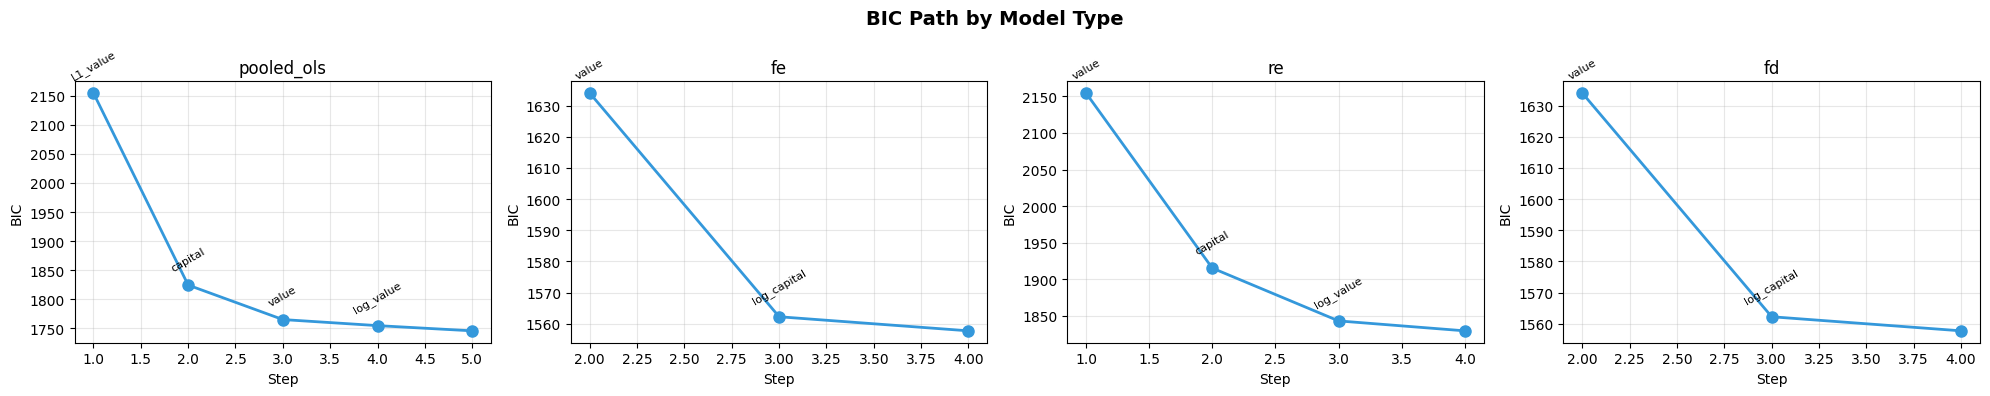

In [10]:
fig, axes = plt.subplots(1, len(results.variable_selection), 
                         figsize=(5 * len(results.variable_selection), 4),
                         squeeze=False)

for idx, (model_type, sel) in enumerate(results.variable_selection.items()):
    ax = axes[0, idx]
    bic_path = sel.get('bic_path', [])
    if bic_path:
        steps = list(range(1, len(bic_path) + 1))
        ax.plot(steps, bic_path, 'o-', color='#3498db', linewidth=2, markersize=8)
        ax.set_xlabel('Step')
        ax.set_ylabel('BIC')
        ax.set_title(f'{model_type} - BIC Path')
        ax.grid(True, alpha=0.3)
        
        # Annotate selected variables
        selected = sel.get('selected_vars', [])
        for i, var in enumerate(selected[:len(bic_path)]):
            ax.annotate(var, (steps[i], bic_path[i]), 
                       textcoords="offset points", xytext=(0, 10),
                       ha='center', fontsize=8, rotation=30)
    else:
        ax.text(0.5, 0.5, 'No BIC path', ha='center', va='center',
                transform=ax.transAxes)
    ax.set_title(f'{model_type}')

plt.suptitle('BIC Path by Model Type', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 9. Exporting Results

Export rankings and results to CSV for further analysis.

In [11]:
# Export ranking table
results.ranking.to_csv("autoexperiment_ranking.csv", index=False)
print("Ranking exported to autoexperiment_ranking.csv")

# Export comparison table
results.compare_top(n=10).to_csv("autoexperiment_top_models.csv", index=False)
print("Top models exported to autoexperiment_top_models.csv")

# Generate HTML report
html = results.report(filepath="autoexperiment_advanced_report.html")
print(f"HTML report saved ({len(html):,} chars)")

Ranking exported to autoexperiment_ranking.csv
Top models exported to autoexperiment_top_models.csv
HTML report saved (3,247 chars)


In [12]:
# Transformations mapping
print("Transformations used:")
for var, (source, ttype) in results.transformations_used.items():
    print(f"  {var} <- {source} ({ttype})")

Transformations used:
  L1_value <- value (lag1)
  D_value <- value (diff)
  log_value <- value (log)
  growth_value <- value (growth)
  L1_capital <- capital (lag1)
  D_capital <- capital (diff)
  log_capital <- capital (log)
  growth_capital <- capital (growth)


## Summary

In this notebook we explored:
- **Custom transformations**: lags, diffs, log, growth rates
- **Sign constraints**: using economic theory to filter models
- **Ranking weights**: adjusting the composite score via `ModelRanker`
- **Required tests**: customizing diagnostic test batteries
- **Search budget**: controlling `max_combinations`
- **Variable analysis**: understanding why variables were selected or rejected
- **BIC path**: visualizing the stepwise selection process
- **Export**: saving results to CSV and HTML

**Next**: See `03_credit_risk_application.ipynb` for a real-world application.